In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder,StandardScaler

from sklearn.metrics import confusion_matrix,accuracy_score,classification_report

In [2]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans

In [3]:
student_features = pd.read_csv('data/processed/student_features_advanced.csv')

In [4]:
student_features.head()

,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,...,engagement_span_days,activity_density,click_std,daily_click_mean,click_cv,unique_sites_visited,clicks_early,clicks_mid,clicks_late,early_engagement_ratio
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,...,258.0,0.155039,27.883411,23.050000,1.209692,55.0,528.0,182.0,212.0,0.572668
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,...,249.0,0.321285,20.565729,17.612500,1.167678,84.0,660.0,443.0,306.0,0.468417
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,...,22.0,0.545455,17.447758,21.666667,0.805281,22.0,260.0,0.0,0.0,1.000000
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,...,274.0,0.448905,14.650752,16.317073,0.897879,82.0,769.0,844.0,394.0,0.383159
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,...,257.0,0.272374,16.464882,14.457143,1.138875,66.0,597.0,249.0,166.0,0.589921


In [5]:
student_features.shape

(32593, 25)

In [6]:
student_features.isnull().sum()

code_module               0
code_presentation         0
id_student                0
gender                    0
region                    0
highest_education         0
imd_band                  0
age_band                  0
num_of_prev_attempts      0
studied_credits           0
disability                0
final_result              0
total_clicks              0
active_days               0
avg_daily_clicks          0
engagement_span_days      0
activity_density          0
click_std                 0
daily_click_mean          0
click_cv                  0
unique_sites_visited      0
clicks_early              0
clicks_mid                0
clicks_late               0
early_engagement_ratio    0
dtype: int64

In [7]:
student_features["final_result"].value_counts()

final_result
Pass           12361
Withdrawn      10156
Fail            7052
Distinction     3024
Name: count, dtype: int64

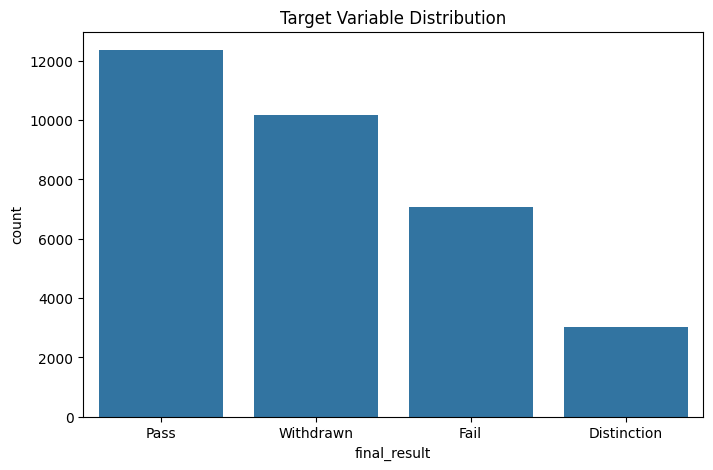

In [8]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=student_features,
    x="final_result"
)

plt.title("Target Variable Distribution")

plt.show()

In [9]:
selected_features = ["studied_credits","total_clicks","active_days","avg_daily_clicks","engagement_span_days","activity_density","click_std","daily_click_mean","click_cv","unique_sites_visited","clicks_early","clicks_mid","clicks_late","early_engagement_ratio"
]

In [10]:
X = student_features[selected_features]

In [11]:
y = student_features["final_result"]

In [12]:
label_encoder=LabelEncoder()
y_encoded=label_encoder.fit_transform(y)

In [13]:
dict(
    zip(
        label_encoder.classes_,    # this is used for checking the encoding
        range(
            len(label_encoder.classes_)
        )
    )
)

{'Distinction': 0, 'Fail': 1, 'Pass': 2, 'Withdrawn': 3}

In [14]:
X_train,X_test,y_train,y_test=train_test_split(
    X,y_encoded,test_size=0.2,random_state=42,stratify=y_encoded
)

In [15]:
#now feature scaling


In [16]:
X = X.replace(
    [np.inf, -np.inf],
    np.nan
)

X = X.fillna(0)

In [18]:
np.isinf(X).sum(axis=0)

studied_credits           0
total_clicks              0
active_days               0
avg_daily_clicks          0
engagement_span_days      0
activity_density          0
click_std                 0
daily_click_mean          0
click_cv                  0
unique_sites_visited      0
clicks_early              0
clicks_mid                0
clicks_late               0
early_engagement_ratio    0
dtype: int64

In [19]:
X_train = X_train.replace([np.inf, -np.inf], 0)
X_test = X_test.replace([np.inf, -np.inf], 0)

X_train = X_train.fillna(0)
X_test = X_test.fillna(0)

In [20]:
print(np.isinf(X_train).sum().sum())
print(X_train.isnull().sum().sum())

0
0


In [21]:
scaler=StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

The problem is there are values inf which we need to get rid of

In [ ]:
np.isinf(X).sum()

studied_credits           0
total_clicks              0
active_days               0
avg_daily_clicks          0
engagement_span_days      0
activity_density          0
click_std                 0
daily_click_mean          0
click_cv                  0
unique_sites_visited      0
clicks_early              0
clicks_mid                0
clicks_late               0
early_engagement_ratio    0
dtype: int64

In [ ]:
np.isinf(X).sum(axis=0)

studied_credits           0
total_clicks              0
active_days               0
avg_daily_clicks          0
engagement_span_days      0
activity_density          0
click_std                 0
daily_click_mean          0
click_cv                  0
unique_sites_visited      0
clicks_early              0
clicks_mid                0
clicks_late               0
early_engagement_ratio    0
dtype: int64

In [22]:
logistic_model=LogisticRegression(max_iter=1000)

In [23]:
logistic_model.fit(X_train_scaled,y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [24]:
print(np.isinf(X_train).sum())

studied_credits           0
total_clicks              0
active_days               0
avg_daily_clicks          0
engagement_span_days      0
activity_density          0
click_std                 0
daily_click_mean          0
click_cv                  0
unique_sites_visited      0
clicks_early              0
clicks_mid                0
clicks_late               0
early_engagement_ratio    0
dtype: int64


In [25]:
print(np.isinf(X_train).sum().sum())
print(X_train.isnull().sum().sum())

0
0


In [26]:
y_pred_logistic=logistic_model.predict(X_test_scaled)

Evaluation of the logistic regression model

In [27]:
accuracy_score(
    y_test,
    y_pred_logistic
)

0.66344531369842

In [28]:
print(
    classification_report(
        y_test,
        y_pred_logistic
    )
)

              precision    recall  f1-score   support

           0       0.48      0.02      0.04       605
           1       0.56      0.26      0.35      1411
           2       0.65      0.96      0.78      2472
           3       0.72      0.78      0.75      2031

    accuracy                           0.66      6519
   macro avg       0.60      0.50      0.48      6519
weighted avg       0.64      0.66      0.61      6519



In [29]:
conf_matrix = confusion_matrix(
    y_test,
    y_pred_logistic
)

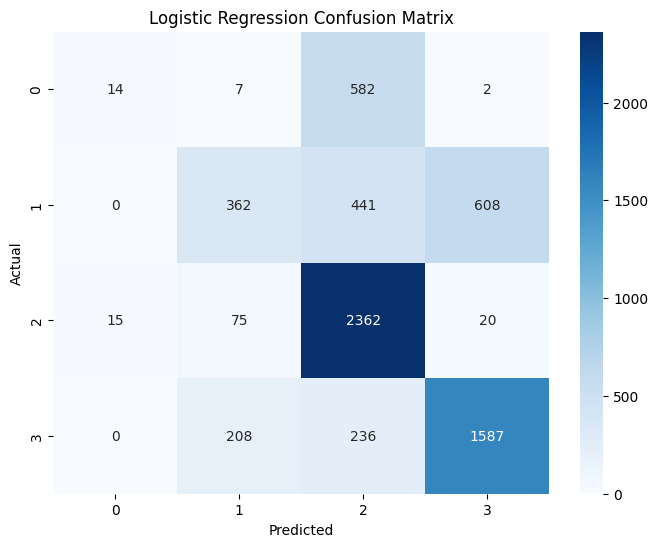

In [30]:
plt.figure(figsize=(8,6))

sns.heatmap(
    conf_matrix,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Logistic Regression Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

We next move to RandomForestRegressor

In [31]:
random_forest_model=RandomForestClassifier(n_estimators=200,random_state=42)

In [32]:
random_forest_model.fit(X_train,y_train)  # cause RandomForest does not require scaling

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [33]:
y_pred_rf=random_forest_model.predict(X_test)

In [34]:
accuracy_score(
    y_test,
    y_pred_rf
)

0.6424298205246204

Let us evaluate the classification model properly and understand confusion_matrix,class_wise_precision and class_wise_recall

In [35]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred_logistic,
        target_names=label_encoder.classes_
    )
)

              precision    recall  f1-score   support

 Distinction       0.48      0.02      0.04       605
        Fail       0.56      0.26      0.35      1411
        Pass       0.65      0.96      0.78      2472
   Withdrawn       0.72      0.78      0.75      2031

    accuracy                           0.66      6519
   macro avg       0.60      0.50      0.48      6519
weighted avg       0.64      0.66      0.61      6519



In [36]:
from sklearn.metrics import confusion_matrix

cm_logistic = confusion_matrix(
    y_test,
    y_pred_logistic
)

cm_logistic

array([[  14,    7,  582,    2],
       [   0,  362,  441,  608],
       [  15,   75, 2362,   20],
       [   0,  208,  236, 1587]])

In [37]:
print(
    classification_report(
        y_test,
        y_pred_rf,
        target_names=label_encoder.classes_
    )
)

              precision    recall  f1-score   support

 Distinction       0.36      0.08      0.13       605
        Fail       0.51      0.33      0.40      1411
        Pass       0.67      0.88      0.76      2472
   Withdrawn       0.68      0.73      0.70      2031

    accuracy                           0.64      6519
   macro avg       0.55      0.51      0.50      6519
weighted avg       0.61      0.64      0.61      6519



In [38]:
cm_rf = confusion_matrix(
    y_test,
    y_pred_rf
)

cm_rf

array([[  50,    9,  525,   21],
       [   5,  471,  385,  550],
       [  67,   96, 2186,  123],
       [  17,  356,  177, 1481]])

In [39]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

comparison = pd.DataFrame({

    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],

    "Accuracy": [
        accuracy_score(
            y_test,
            y_pred_logistic
        ),

        accuracy_score(
            y_test,
            y_pred_rf
        )
    ],

    "Precision": [
        precision_score(
            y_test,
            y_pred_logistic,
            average="weighted"
        ),

        precision_score(
            y_test,
            y_pred_rf,
            average="weighted"
        )
    ],

    "Recall": [
        recall_score(
            y_test,
            y_pred_logistic,
            average="weighted"
        ),

        recall_score(
            y_test,
            y_pred_rf,
            average="weighted"
        )
    ],

    "F1 Score": [
        f1_score(
            y_test,
            y_pred_logistic,
            average="weighted"
        ),

        f1_score(
            y_test,
            y_pred_rf,
            average="weighted"
        )
    ]
})

comparison

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.663445,0.635348,0.663445,0.606841
1,Random Forest,0.642430,0.608171,0.642430,0.607473


In [40]:
assessments = pd.read_csv("assessments.csv")
studentAssessment = pd.read_csv("studentAssessment.csv")

In [41]:
print(assessments.shape)
print(studentAssessment.shape)

assessments.head()

(206, 6)
(173912, 5)


,code_module,code_presentation,id_assessment,assessment_type,date,weight
0,AAA,2013J,1752,TMA,19.0,10.0
1,AAA,2013J,1753,TMA,54.0,20.0
2,AAA,2013J,1754,TMA,117.0,20.0
3,AAA,2013J,1755,TMA,166.0,20.0
4,AAA,2013J,1756,TMA,215.0,30.0


In [42]:
assessment_data = studentAssessment.merge(
    assessments,
    on="id_assessment",
    how="left"
)

assessment_data.head()

,id_assessment,id_student,date_submitted,is_banked,score,code_module,code_presentation,assessment_type,date,weight
0,1752,11391,18,0,78.0,AAA,2013J,TMA,19.0,10.0
1,1752,28400,22,0,70.0,AAA,2013J,TMA,19.0,10.0
2,1752,31604,17,0,72.0,AAA,2013J,TMA,19.0,10.0
3,1752,32885,26,0,69.0,AAA,2013J,TMA,19.0,10.0
4,1752,38053,19,0,79.0,AAA,2013J,TMA,19.0,10.0


In [43]:
assessment_data["weighted_score"] = (
    assessment_data["score"]
    * assessment_data["weight"]
) / 100

In [44]:
performance_features = (
    assessment_data
    .groupby("id_student")
    .agg({
        "score": [
            "mean",
            "median",
            "max",
            "min",
            "std",
            "count"
        ],
        "weighted_score": [
            "sum",
            "mean"
        ]
    })
)

In [45]:
performance_features.columns = [
    "assessment_mean_score",
    "assessment_median_score",
    "assessment_max_score",
    "assessment_min_score",
    "assessment_std_score",
    "assessment_count",
    "weighted_score_total",
    "weighted_score_mean"
]

performance_features = (
    performance_features
    .reset_index()
)

performance_features.head()

,id_student,assessment_mean_score,assessment_median_score,assessment_max_score,assessment_min_score,assessment_std_score,assessment_count,weighted_score_total,weighted_score_mean
0,6516,61.800000,61.0,77.0,48.0,10.329569,5,63.50,12.700000
1,8462,87.000000,87.0,93.0,83.0,4.472136,7,77.90,11.128571
2,11391,82.000000,82.0,85.0,78.0,3.082207,5,82.40,16.480000
3,23629,82.500000,83.5,100.0,63.0,20.273135,4,16.69,4.172500
4,23698,74.444444,73.0,94.0,56.0,13.258121,9,149.97,16.663333


In [46]:
submission_features = (
    assessment_data
    .groupby("id_student")
    .agg({
        "date_submitted": [
            "mean",
            "min",
            "max",
            "std"
        ]
    })
)

In [47]:
submission_features.columns = [
    "avg_submission_day",
    "first_submission_day",
    "last_submission_day",
    "submission_day_std"
]

submission_features = (
    submission_features
    .reset_index()
)

In [48]:
assessment_features = performance_features.merge(
    submission_features,
    on="id_student",
    how="left"
)

assessment_features.head()

,id_student,assessment_mean_score,assessment_median_score,assessment_max_score,assessment_min_score,assessment_std_score,assessment_count,weighted_score_total,weighted_score_mean,avg_submission_day,first_submission_day,last_submission_day,submission_day_std
0,6516,61.800000,61.0,77.0,48.0,10.329569,5,63.50,12.700000,111.600000,17,210,79.166281
1,8462,87.000000,87.0,93.0,83.0,4.472136,7,77.90,11.128571,23.000000,-1,85,34.078341
2,11391,82.000000,82.0,85.0,78.0,3.082207,5,82.40,16.480000,112.400000,18,212,79.103097
3,23629,82.500000,83.5,100.0,63.0,20.273135,4,16.69,4.172500,55.750000,9,95,35.377724
4,23698,74.444444,73.0,94.0,56.0,13.258121,9,149.97,16.663333,133.444444,21,243,81.911707


In [49]:
student_features_v2 = student_features.merge(
    assessment_features,
    on="id_student",
    how="left"
)

In [50]:
student_features_v2 = (
    student_features_v2
    .fillna(0)
)

In [51]:
student_features_v2.shape

(32593, 37)

In [52]:
student_features_v2.columns.tolist()

['code_module',
 'code_presentation',
 'id_student',
 'gender',
 'region',
 'highest_education',
 'imd_band',
 'age_band',
 'num_of_prev_attempts',
 'studied_credits',
 'disability',
 'final_result',
 'total_clicks',
 'active_days',
 'avg_daily_clicks',
 'engagement_span_days',
 'activity_density',
 'click_std',
 'daily_click_mean',
 'click_cv',
 'unique_sites_visited',
 'clicks_early',
 'clicks_mid',
 'clicks_late',
 'early_engagement_ratio',
 'assessment_mean_score',
 'assessment_median_score',
 'assessment_max_score',
 'assessment_min_score',
 'assessment_std_score',
 'assessment_count',
 'weighted_score_total',
 'weighted_score_mean',
 'avg_submission_day',
 'first_submission_day',
 'last_submission_day',
 'submission_day_std']

In [53]:
selected_features = [

    # Behavioral Features

    "studied_credits",

    "total_clicks",

    "active_days",

    "avg_daily_clicks",

    "engagement_span_days",

    "activity_density",

    "click_std",

    "daily_click_mean",

    "click_cv",

    "unique_sites_visited",

    "clicks_early",

    "clicks_mid",

    "clicks_late",

    "early_engagement_ratio",

    # Assessment Features

    "assessment_mean_score",

    "assessment_median_score",

    "assessment_max_score",

    "assessment_min_score",

    "assessment_std_score",

    "assessment_count",

    "weighted_score_total",

    "weighted_score_mean",

    "avg_submission_day",

    "first_submission_day",

    "last_submission_day",

    "submission_day_std"
]

In [54]:
X = student_features_v2[selected_features]

y = student_features_v2["final_result"]

In [55]:
X.isnull().sum().sort_values(ascending=False).head(20)

studied_credits            0
total_clicks               0
active_days                0
avg_daily_clicks           0
engagement_span_days       0
activity_density           0
click_std                  0
daily_click_mean           0
click_cv                   0
unique_sites_visited       0
clicks_early               0
clicks_mid                 0
clicks_late                0
early_engagement_ratio     0
assessment_mean_score      0
assessment_median_score    0
assessment_max_score       0
assessment_min_score       0
assessment_std_score       0
assessment_count           0
dtype: int64

In [56]:
np.isinf(X).sum()

studied_credits              0
total_clicks                 0
active_days                  0
avg_daily_clicks             0
engagement_span_days         0
activity_density           630
click_std                    0
daily_click_mean             0
click_cv                     0
unique_sites_visited         0
clicks_early                 0
clicks_mid                   0
clicks_late                  0
early_engagement_ratio       0
assessment_mean_score        0
assessment_median_score      0
assessment_max_score         0
assessment_min_score         0
assessment_std_score         0
assessment_count             0
weighted_score_total         0
weighted_score_mean          0
avg_submission_day           0
first_submission_day         0
last_submission_day          0
submission_day_std           0
dtype: int64

In [57]:
np.isinf(X).sum().sum()

np.int64(630)

In [58]:
X = X.replace(
    [np.inf, -np.inf],
    0
)

In [59]:
np.isinf(X).sum().sum()

np.int64(0)

In [61]:
X = student_features_v2[selected_features]

y = student_features_v2["final_result"]

In [62]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

In [63]:
mapping = dict(
    zip(
        label_encoder.classes_,
        range(len(label_encoder.classes_))
    )
)

mapping

{'Distinction': 0, 'Fail': 1, 'Pass': 2, 'Withdrawn': 3}

In [64]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = (
    train_test_split(
        X,
        y_encoded,
        test_size=0.20,
        random_state=42,
        stratify=y_encoded
    )
)

In [66]:
print(X_train.shape)
print(X_test.shape)

(26074, 26)
(6519, 26)


In [68]:
X = X.replace(
    [np.inf, -np.inf],
    0
)

In [69]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

ValueError: Input X contains infinity or a value too large for dtype('float64').

In [70]:
import numpy as np

inf_counts = pd.Series(
    np.isinf(X).sum(),
    index=X.columns
)

inf_counts[inf_counts > 0]

Series([], dtype: int64)

In [71]:
X = X.replace(
    [np.inf, -np.inf],
    np.nan
)

In [72]:
X = X.fillna(0)

In [73]:
print(np.isinf(X).sum().sum())
print(X.isnull().sum().sum())

0
0


In [74]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

ValueError: Input X contains infinity or a value too large for dtype('float64').

In [75]:
X.max().sort_values(ascending=False).head(20)

total_clicks               27922.000000
clicks_mid                 13204.000000
clicks_late                12399.000000
clicks_early               11190.000000
click_std                    704.691214
studied_credits              655.000000
last_submission_day          608.000000
unique_sites_visited         579.000000
weighted_score_total         477.190000
avg_submission_day           315.555556
engagement_span_days         294.000000
active_days                  286.000000
submission_day_std           264.354455
first_submission_day         241.000000
avg_daily_clicks             156.529412
daily_click_mean             156.529412
assessment_mean_score        100.000000
assessment_min_score         100.000000
assessment_median_score      100.000000
assessment_max_score         100.000000
dtype: float64

In [76]:
X.min().sort_values().head(20)

first_submission_day      -11.0
avg_submission_day         -4.0
last_submission_day        -4.0
total_clicks                0.0
click_std                   0.0
active_days                 0.0
avg_daily_clicks            0.0
engagement_span_days        0.0
clicks_late                 0.0
unique_sites_visited        0.0
clicks_early                0.0
clicks_mid                  0.0
assessment_mean_score       0.0
activity_density            0.0
daily_click_mean            0.0
click_cv                    0.0
weighted_score_total        0.0
assessment_median_score     0.0
early_engagement_ratio      0.0
assessment_max_score        0.0
dtype: float64

In [77]:
inf_counts = pd.Series(
    np.isinf(X).sum(),
    index=X.columns
)

inf_counts[inf_counts > 0]

Series([], dtype: int64)

In [78]:
X_train = X_train.replace([np.inf, -np.inf], np.nan)
X_test = X_test.replace([np.inf, -np.inf], np.nan)

X_train = X_train.fillna(0)
X_test = X_test.fillna(0)

In [79]:
X_train = X_train.astype(np.float64)
X_test = X_test.astype(np.float64)

X_train = np.nan_to_num(
    X_train,
    nan=0,
    posinf=0,
    neginf=0
)

X_test = np.nan_to_num(
    X_test,
    nan=0,
    posinf=0,
    neginf=0
)

In [80]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [81]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    max_iter=2000,
    random_state=42
)

In [82]:
logistic_model.fit(
    X_train_scaled,
    y_train
)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multi

In [83]:
y_pred_logistic = logistic_model.predict(
    X_test_scaled
)

In [84]:
from sklearn.metrics import accuracy_score

logistic_accuracy = accuracy_score(
    y_test,
    y_pred_logistic
)

print(
    "Logistic Accuracy:",
    logistic_accuracy
)

Logistic Accuracy: 0.6921306948918545


In [85]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred_logistic,
        target_names=label_encoder.classes_
    )
)

              precision    recall  f1-score   support

 Distinction       0.65      0.40      0.49       605
        Fail       0.57      0.30      0.39      1411
        Pass       0.71      0.90      0.80      2472
   Withdrawn       0.71      0.80      0.75      2031

    accuracy                           0.69      6519
   macro avg       0.66      0.60      0.61      6519
weighted avg       0.67      0.69      0.67      6519



In [86]:
from sklearn.metrics import confusion_matrix

cm_logistic = confusion_matrix(
    y_test,
    y_pred_logistic
)

cm_logistic

array([[ 240,    0,  365,    0],
       [   1,  422,  355,  633],
       [ 121,   86, 2233,   32],
       [   8,  235,  171, 1617]])

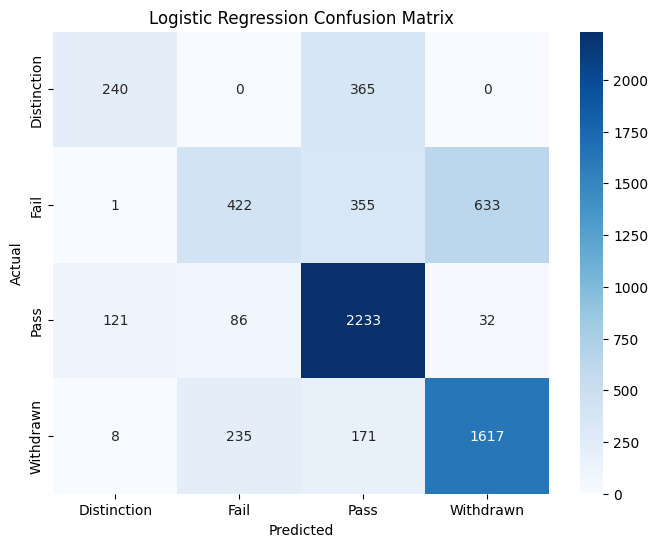

In [87]:
plt.figure(figsize=(8,6))

sns.heatmap(
    cm_logistic,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title(
    "Logistic Regression Confusion Matrix"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [88]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=500,
    max_depth=15,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

In [89]:
rf_model.fit(
    X_train,
    y_train
)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",500
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",15
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",5
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y

In [90]:
y_pred_rf = rf_model.predict(
    X_test
)

In [91]:
rf_accuracy = accuracy_score(
    y_test,
    y_pred_rf
)

print(
    "Random Forest Accuracy:",
    rf_accuracy
)

Random Forest Accuracy: 0.7062432888479828


In [92]:
print(
    classification_report(
        y_test,
        y_pred_rf,
        target_names=label_encoder.classes_
    )
)

              precision    recall  f1-score   support

 Distinction       0.68      0.47      0.56       605
        Fail       0.60      0.40      0.48      1411
        Pass       0.74      0.90      0.81      2472
   Withdrawn       0.71      0.75      0.73      2031

    accuracy                           0.71      6519
   macro avg       0.68      0.63      0.65      6519
weighted avg       0.70      0.71      0.69      6519



In [93]:
cm_rf = confusion_matrix(
    y_test,
    y_pred_rf
)

cm_rf

array([[ 286,    1,  307,   11],
       [   1,  570,  290,  550],
       [ 119,   56, 2228,   69],
       [  13,  324,  174, 1520]])

In [94]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

comparison = pd.DataFrame({

    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],

    "Accuracy": [
        accuracy_score(
            y_test,
            y_pred_logistic
        ),
        accuracy_score(
            y_test,
            y_pred_rf
        )
    ],

    "Precision": [
        precision_score(
            y_test,
            y_pred_logistic,
            average="weighted"
        ),
        precision_score(
            y_test,
            y_pred_rf,
            average="weighted"
        )
    ],

    "Recall": [
        recall_score(
            y_test,
            y_pred_logistic,
            average="weighted"
        ),
        recall_score(
            y_test,
            y_pred_rf,
            average="weighted"
        )
    ],

    "F1 Score": [
        f1_score(
            y_test,
            y_pred_logistic,
            average="weighted"
        ),
        f1_score(
            y_test,
            y_pred_rf,
            average="weighted"
        )
    ]
})

comparison

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.692131,0.674940,0.692131,0.666735
1,Random Forest,0.706243,0.695049,0.706243,0.691683


In [95]:
feature_importance = pd.DataFrame({

    "Feature": X.columns,

    "Importance":
    rf_model.feature_importances_
})

In [96]:
feature_importance = (
    feature_importance
    .sort_values(
        by="Importance",
        ascending=False
    )
)

feature_importance.head(20)

,Feature,Importance
22,avg_submission_day,0.122443
12,clicks_late,0.096245
24,last_submission_day,0.078665
4,engagement_span_days,0.075466
20,weighted_score_total,0.059196
14,assessment_mean_score,0.058441
25,submission_day_std,0.050540
19,assessment_count,0.038365
15,assessment_median_score,0.037435
17,assessment_min_score,0.035601


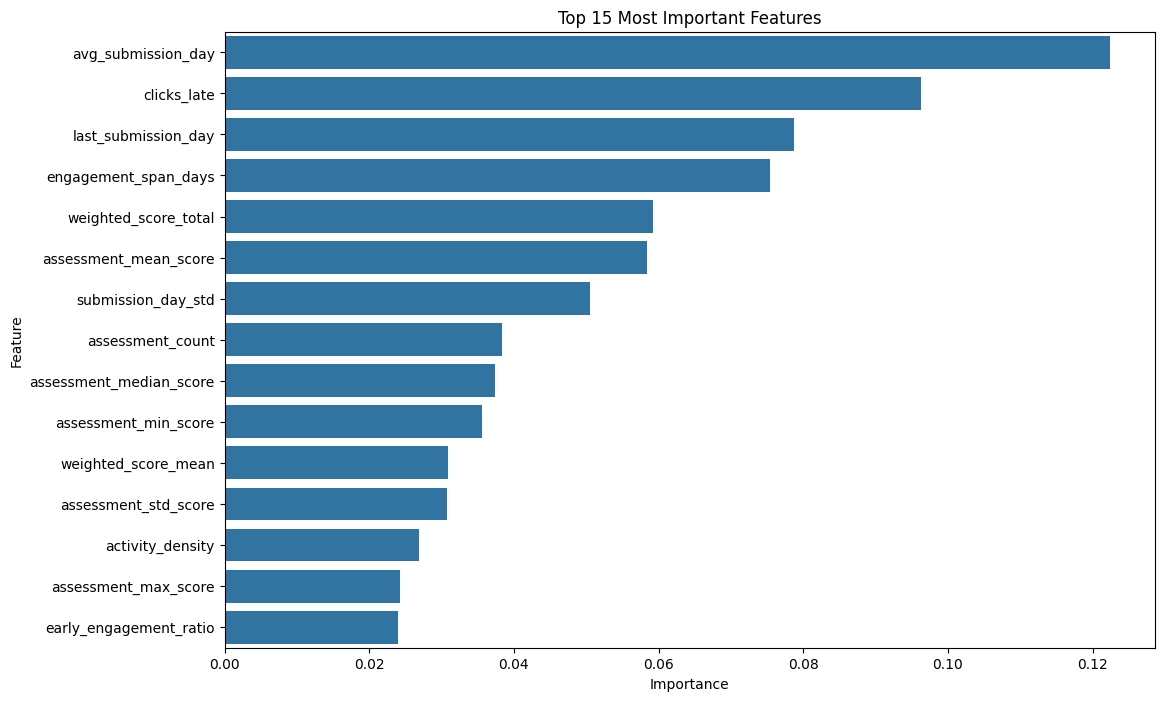

In [97]:
plt.figure(figsize=(12,8))

sns.barplot(
    data=feature_importance.head(15),
    x="Importance",
    y="Feature"
)

plt.title(
    "Top 15 Most Important Features"
)

plt.show()

In [98]:
import os

os.makedirs("data/processed", exist_ok=True)
os.makedirs("models", exist_ok=True)

In [107]:
print(student_features.shape)

student_features.columns.tolist()

(32593, 25)


['code_module',
 'code_presentation',
 'id_student',
 'gender',
 'region',
 'highest_education',
 'imd_band',
 'age_band',
 'num_of_prev_attempts',
 'studied_credits',
 'disability',
 'final_result',
 'total_clicks',
 'active_days',
 'avg_daily_clicks',
 'engagement_span_days',
 'activity_density',
 'click_std',
 'daily_click_mean',
 'click_cv',
 'unique_sites_visited',
 'clicks_early',
 'clicks_mid',
 'clicks_late',
 'early_engagement_ratio']

In [99]:
student_features.to_csv(
    "data/processed/student_features_final.csv",
    index=False
)

print("student_features_final.csv saved")

student_features_final.csv saved


In [100]:
feature_importance_df = pd.DataFrame({
    "feature": X.columns,
    "importance": rf_model.feature_importances_
})

feature_importance_df = (
    feature_importance_df
    .sort_values(
        by="importance",
        ascending=False
    )
)

In [101]:
feature_importance_df.to_csv(
    "data/processed/feature_importance.csv",
    index=False
)

print("feature_importance.csv saved")

feature_importance.csv saved


In [102]:
prediction_df = pd.DataFrame({
    "actual_result": y_test,
    "predicted_result": y_pred_rf
})

prediction_df.to_csv(
    "data/processed/student_predictions.csv",
    index=False
)

print("student_predictions.csv saved")

student_predictions.csv saved


In [103]:
import joblib

joblib.dump(
    rf_model,
    "models/random_forest.pkl"
)

print("random_forest.pkl saved")

random_forest.pkl saved


In [104]:
joblib.dump(
    label_encoder,
    "models/label_encoder.pkl"
)

print("label_encoder.pkl saved")

label_encoder.pkl saved


In [105]:
joblib.dump(
    scaler,
    "models/scaler.pkl"
)

print("scaler.pkl saved")

scaler.pkl saved


In [106]:
import os

print("\nDATA FILES")
print(os.listdir("data/processed"))

print("\nMODEL FILES")
print(os.listdir("models"))


DATA FILES
['feature_importance.csv', 'student_features_advanced.csv', 'student_features_final.csv', 'student_predictions.csv']

MODEL FILES
['label_encoder.pkl', 'random_forest.pkl', 'scaler.pkl']


We have encountered a problem with the student_features file where there is no features there were expecte to be 37+ columns but there are only 25 so we need to merge them so that we can perform clustering in a much better way and get optimal results

In [108]:
student_assessment = pd.read_csv("studentAssessment.csv")
assessments = pd.read_csv("assessments.csv")

In [109]:
assessment_df = student_assessment.merge(
    assessments,
    on=["id_assessment", "code_module", "code_presentation"],
    how="left"
)

assessment_df.head()

KeyError: 'code_module'

In [110]:
student_assessment.columns.tolist()

['id_assessment', 'id_student', 'date_submitted', 'is_banked', 'score']

In [111]:
assessments.columns.tolist()

['code_module',
 'code_presentation',
 'id_assessment',
 'assessment_type',
 'date',
 'weight']

running cells through A1 to A10

In [112]:
assessment_df = student_assessment.merge(
    assessments,
    on="id_assessment",
    how="left"
)

print(assessment_df.shape)

assessment_df.head()

(173912, 10)


,id_assessment,id_student,date_submitted,is_banked,score,code_module,code_presentation,assessment_type,date,weight
0,1752,11391,18,0,78.0,AAA,2013J,TMA,19.0,10.0
1,1752,28400,22,0,70.0,AAA,2013J,TMA,19.0,10.0
2,1752,31604,17,0,72.0,AAA,2013J,TMA,19.0,10.0
3,1752,32885,26,0,69.0,AAA,2013J,TMA,19.0,10.0
4,1752,38053,19,0,79.0,AAA,2013J,TMA,19.0,10.0


In [113]:
assessment_df.isnull().sum()

id_assessment           0
id_student              0
date_submitted          0
is_banked               0
score                 173
code_module             0
code_presentation       0
assessment_type         0
date                 2865
weight                  0
dtype: int64

In [114]:
assessment_df["weighted_score"] = (
    assessment_df["score"] *
    assessment_df["weight"]
) / 100

In [115]:
assessment_features = (
    assessment_df
    .groupby(
        [
            "code_module",
            "code_presentation",
            "id_student"
        ]
    )
    .agg(
        assessment_mean_score=("score", "mean"),
        assessment_median_score=("score", "median"),
        assessment_max_score=("score", "max"),
        assessment_min_score=("score", "min"),
        assessment_std_score=("score", "std"),
        assessment_count=("score", "count")
    )
    .reset_index()
)

assessment_features.head()

,code_module,code_presentation,id_student,assessment_mean_score,assessment_median_score,assessment_max_score,assessment_min_score,assessment_std_score,assessment_count
0,AAA,2013J,11391,82.0,82.0,85.0,78.0,3.082207,5
1,AAA,2013J,28400,66.4,68.0,70.0,60.0,4.335897,5
2,AAA,2013J,31604,76.0,74.0,88.0,71.0,6.892024,5
3,AAA,2013J,32885,54.4,63.0,75.0,30.0,20.513410,5
4,AAA,2013J,38053,68.0,69.0,79.0,50.0,10.977249,5


In [116]:
submission_features = (
    assessment_df
    .groupby(
        [
            "code_module",
            "code_presentation",
            "id_student"
        ]
    )
    .agg(
        avg_submission_day=("date_submitted", "mean"),
        first_submission_day=("date_submitted", "min"),
        last_submission_day=("date_submitted", "max"),
        submission_day_std=("date_submitted", "std")
    )
    .reset_index()
)

submission_features.head()

,code_module,code_presentation,id_student,avg_submission_day,first_submission_day,last_submission_day,submission_day_std
0,AAA,2013J,11391,112.4,18,212,79.103097
1,AAA,2013J,28400,114.2,22,212,78.199744
2,AAA,2013J,31604,112.2,17,213,80.257087
3,AAA,2013J,32885,125.6,26,222,78.811801
4,AAA,2013J,38053,116.2,19,215,78.126180


In [118]:
weighted_features = (
    assessment_df
    .groupby(
        [
            "code_module",
            "code_presentation",
            "id_student"
        ]
    )
    .agg(
        weighted_score_total=("weighted_score", "sum"),
        weighted_score_mean=("weighted_score", "mean")
    )
    .reset_index()
)

weighted_features.head()

,code_module,code_presentation,id_student,weighted_score_total,weighted_score_mean
0,AAA,2013J,11391,82.4,16.48
1,AAA,2013J,28400,65.4,13.08
2,AAA,2013J,31604,76.3,15.26
3,AAA,2013J,32885,55.0,11.00
4,AAA,2013J,38053,66.9,13.38


In [119]:
print("Assessment Features:", assessment_features.shape)
print("Weighted Features:", weighted_features.shape)
print("Submission Features:", submission_features.shape)

Assessment Features: (25843, 9)
Weighted Features: (25843, 5)
Submission Features: (25843, 7)


In [120]:
submission_features = (
    assessment_df
    .groupby(
        [
            "code_module",
            "code_presentation",
            "id_student"
        ]
    )
    .agg(
        avg_submission_day=("date_submitted", "mean"),
        first_submission_day=("date_submitted", "min"),
        last_submission_day=("date_submitted", "max"),
        submission_day_std=("date_submitted", "std")
    )
    .reset_index()
)

submission_features.head()

,code_module,code_presentation,id_student,avg_submission_day,first_submission_day,last_submission_day,submission_day_std
0,AAA,2013J,11391,112.4,18,212,79.103097
1,AAA,2013J,28400,114.2,22,212,78.199744
2,AAA,2013J,31604,112.2,17,213,80.257087
3,AAA,2013J,32885,125.6,26,222,78.811801
4,AAA,2013J,38053,116.2,19,215,78.126180


In [121]:
print("Assessment Features:", assessment_features.shape)
print("Weighted Features:", weighted_features.shape)
print("Submission Features:", submission_features.shape)

Assessment Features: (25843, 9)
Weighted Features: (25843, 5)
Submission Features: (25843, 7)


In [122]:
student_features = student_features.merge(
    assessment_features,
    on=[
        "code_module",
        "code_presentation",
        "id_student"
    ],
    how="left"
)

student_features = student_features.merge(
    weighted_features,
    on=[
        "code_module",
        "code_presentation",
        "id_student"
    ],
    how="left"
)

student_features = student_features.merge(
    submission_features,
    on=[
        "code_module",
        "code_presentation",
        "id_student"
    ],
    how="left"
)

In [123]:
new_cols = [

    "assessment_mean_score",
    "assessment_median_score",
    "assessment_max_score",
    "assessment_min_score",
    "assessment_std_score",
    "assessment_count",

    "weighted_score_total",
    "weighted_score_mean",

    "avg_submission_day",
    "first_submission_day",
    "last_submission_day",
    "submission_day_std"
]

student_features[new_cols] = (
    student_features[new_cols]
    .fillna(0)
)

In [124]:
print(student_features.shape)

student_features.columns.tolist()

(32593, 37)


['code_module',
 'code_presentation',
 'id_student',
 'gender',
 'region',
 'highest_education',
 'imd_band',
 'age_band',
 'num_of_prev_attempts',
 'studied_credits',
 'disability',
 'final_result',
 'total_clicks',
 'active_days',
 'avg_daily_clicks',
 'engagement_span_days',
 'activity_density',
 'click_std',
 'daily_click_mean',
 'click_cv',
 'unique_sites_visited',
 'clicks_early',
 'clicks_mid',
 'clicks_late',
 'early_engagement_ratio',
 'assessment_mean_score',
 'assessment_median_score',
 'assessment_max_score',
 'assessment_min_score',
 'assessment_std_score',
 'assessment_count',
 'weighted_score_total',
 'weighted_score_mean',
 'avg_submission_day',
 'first_submission_day',
 'last_submission_day',
 'submission_day_std']

In [125]:
student_features.to_csv(
    "data/processed/student_features_final.csv",
    index=False
)

print("Updated student_features_final.csv saved successfully")

Updated student_features_final.csv saved successfully


IMPLEMENTING NEURAL NETWORKS TO GO A STEP AHEAD 

In [126]:
import tensorflow as tf

from tensorflow.keras.models import Sequential

from tensorflow.keras.layers import (
    Dense,
    Dropout,
    BatchNormalization
)

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau
)

from tensorflow.keras.utils import to_categorical

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

In [133]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

from tensorflow.keras.utils import to_categorical

y_train_nn = to_categorical(y_train)

y_test_nn = to_categorical(y_test)

print(y_train_nn.shape)
print(y_test_nn.shape)

(26074, 4)
(6519, 4)


In [130]:
y_train_nn = to_categorical(y_train_encoded)

y_test_nn = to_categorical(y_test_encoded)

print(y_train_nn.shape)
print(y_test_nn.shape)

(26074, 4)
(6519, 4)


In [132]:
print(type(y_train))
print(type(y_test))

<class 'numpy.ndarray'>
<class 'numpy.ndarray'>


In [131]:
print(y_train[:10])
print(y_train.dtype)

[3 2 3 2 0 0 2 2 1 2]
int64


In [134]:
input_dim = X_train_scaled.shape[1]

print(input_dim)

26


In [135]:
nn_model = Sequential([
    
    Dense(
        128,
        activation="relu",
        input_shape=(input_dim,)
    ),

    BatchNormalization(),

    Dropout(0.30),

    Dense(
        64,
        activation="relu"
    ),

    BatchNormalization(),

    Dropout(0.25),

    Dense(
        32,
        activation="relu"
    ),

    Dense(
        4,
        activation="softmax"
    )
])

c:\Users\vishw\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [136]:
nn_model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

nn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         3,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,692 (57.39 KB)

 Trainable params: 14,308 (55.89 KB)

 Non-trainable params: 384 (1.50 KB)

In [137]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=5,
    verbose=1
)

In [138]:
history = nn_model.fit(

    X_train_scaled,
    y_train_nn,

    validation_split=0.20,

    epochs=100,

    batch_size=256,

    callbacks=[
        early_stopping,
        reduce_lr
    ],

    verbose=1
)

Epoch 1/100
82/82 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.6050 - loss: 0.9695 - val_accuracy: 0.6439 - val_loss: 0.8832 - learning_rate: 0.0010
Epoch 2/100
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.6559 - loss: 0.7868 - val_accuracy: 0.6777 - val_loss: 0.7638 - learning_rate: 0.0010
Epoch 3/100
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.6655 - loss: 0.7478 - val_accuracy: 0.6928 - val_loss: 0.7060 - learning_rate: 0.0010
Epoch 4/100
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.6773 - loss: 0.7305 - val_accuracy: 0.6959 - val_loss: 0.6883 - learning_rate: 0.0010
Epoch 5/100
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.6804 - loss: 0.7154 - val_accuracy: 0.7012 - val_loss: 0.6758 - learning_rate: 0.0010
Epoch 6/100
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.6823 - loss: 0.7066 - val_accuracy: 0.7039 - val_loss: 0.6714 - learning_rate: 0.0010
Epoch 7/100
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.6866 - loss: 0.6979 - val_ac

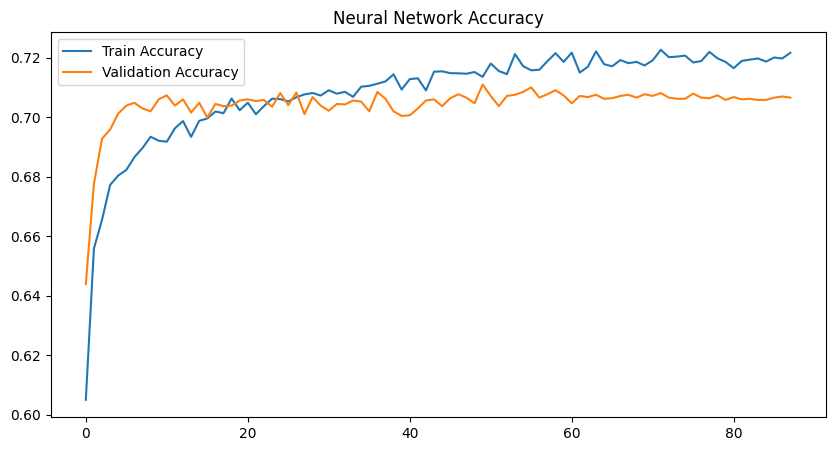

In [139]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

plt.plot(
    history.history["accuracy"],
    label="Train Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.legend()

plt.title(
    "Neural Network Accuracy"
)

plt.show()

In [140]:
y_pred_prob = nn_model.predict(
    X_test_scaled
)

y_pred_nn = y_pred_prob.argmax(axis=1)

204/204 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


In [142]:
from sklearn.metrics import accuracy_score

nn_accuracy = accuracy_score(
    y_test,
    y_pred_nn
)

print(
    "Neural Network Accuracy:",
    round(nn_accuracy, 4)
)

Neural Network Accuracy: 0.715


In [143]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred_nn
    )
)

              precision    recall  f1-score   support

           0       0.67      0.49      0.57       605
           1       0.61      0.40      0.48      1411
           2       0.76      0.89      0.82      2472
           3       0.71      0.79      0.75      2031

    accuracy                           0.71      6519
   macro avg       0.69      0.64      0.65      6519
weighted avg       0.70      0.71      0.70      6519



In [144]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    y_pred_nn
)

print(cm)

[[ 299    0  296   10]
 [   0  566  267  578]
 [ 138   79 2201   54]
 [  10  287  139 1595]]


TRAINING USING GRADIENT BOOSTING

In [145]:
from sklearn.ensemble import GradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

import seaborn as sns
import matplotlib.pyplot as plt

In [146]:
gb_model = GradientBoostingClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=5,
    random_state=42
)

gb_model

,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.05
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",300
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'The function to measure the quality of a split. Supported criteria are'friedman_mse' for the mean squared error with improvement score byFriedman, 'squared_error' for mean squared error. The default value of'friedman_mse' is generally the best as it can provide a betterapproximation in some cases... versionadded:: 0.18",'friedman_mse'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",5
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``,

In [147]:
gb_model.fit(
    X_train_scaled,
    y_train
)

print("Gradient Boosting Training Complete")

Gradient Boosting Training Complete


In [148]:
y_pred_gb = gb_model.predict(
    X_test_scaled
)

In [149]:
gb_accuracy = accuracy_score(
    y_test,
    y_pred_gb
)

print(
    "Gradient Boosting Accuracy:",
    round(gb_accuracy, 4)
)

Gradient Boosting Accuracy: 0.7072


In [152]:
class_names = [
    "Distinction",
    "Fail",
    "Pass",
    "Withdrawn"
]

print(
    classification_report(
        y_test,
        y_pred_gb,
        target_names=class_names
    )
)

              precision    recall  f1-score   support

 Distinction       0.63      0.53      0.58       605
        Fail       0.59      0.44      0.50      1411
        Pass       0.76      0.87      0.81      2472
   Withdrawn       0.71      0.75      0.73      2031

    accuracy                           0.71      6519
   macro avg       0.67      0.65      0.66      6519
weighted avg       0.70      0.71      0.70      6519



In [153]:
gb_cm = confusion_matrix(
    y_test,
    y_pred_gb
)

gb_cm

array([[ 322,    2,  269,   12],
       [   4,  615,  254,  538],
       [ 166,   90, 2143,   73],
       [  16,  337,  148, 1530]])

LET US IMPLEMENT XGBOOST WHICH IS VERY MUCH EFFICIENT AND POWERFUL

In [154]:
pip install xgboost

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [155]:
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

In [156]:
print(np.unique(y_train))
print(np.unique(y_test))

[0 1 2 3]
[0 1 2 3]


In [157]:
xgb_model = XGBClassifier(

    objective="multi:softmax",

    num_class=4,

    n_estimators=500,

    max_depth=6,

    learning_rate=0.05,

    subsample=0.8,

    colsample_bytree=0.8,

    random_state=42,

    n_jobs=-1,

    eval_metric="mlogloss"
)

xgb_model

,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'multi:softmax'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes fro

In [159]:
xgb_model.fit(
    X_train_scaled,
    y_train
)

print("XGBoost Training Complete")

XGBoost Training Complete


In [160]:
y_pred_xgb = xgb_model.predict(
    X_test_scaled
)

In [161]:
y_pred_xgb = xgb_model.predict(
    X_test_scaled
)

In [162]:
xgb_accuracy = accuracy_score(
    y_test,
    y_pred_xgb
)

print(
    "XGBoost Accuracy:",
    round(xgb_accuracy, 4)
)

XGBoost Accuracy: 0.7064


In [163]:
print(
    classification_report(
        y_test,
        y_pred_xgb,
        target_names=[
            "Distinction",
            "Fail",
            "Pass",
            "Withdrawn"
        ]
    )
)

              precision    recall  f1-score   support

 Distinction       0.66      0.53      0.59       605
        Fail       0.59      0.44      0.50      1411
        Pass       0.76      0.88      0.82      2472
   Withdrawn       0.70      0.74      0.72      2031

    accuracy                           0.71      6519
   macro avg       0.68      0.64      0.66      6519
weighted avg       0.70      0.71      0.70      6519



In [164]:
xgb_cm = confusion_matrix(
    y_test,
    y_pred_xgb
)

xgb_cm

array([[ 318,    4,  266,   17],
       [   3,  614,  248,  546],
       [ 143,   69, 2165,   95],
       [  15,  352,  156, 1508]])

SHAP EXPLAINER

In [165]:
pip install shap

   ---------------------------------------- 0.0/38.1 MB ? eta -:--:--
   - -------------------------------------- 1.0/38.1 MB 5.6 MB/s eta 0:00:07
   -- ------------------------------------- 2.6/38.1 MB 6.3 MB/s eta 0:00:06
   ---- ----------------------------------- 4.2/38.1 MB 6.7 MB/s eta 0:00:06
   ------ --------------------------------- 6.0/38.1 MB 7.1 MB/s eta 0:00:05
   ------- -------------------------------- 7.6/38.1 MB 7.0 MB/s eta 0:00:05
   --------- ------------------------------ 9.2/38.1 MB 7.1 MB/s eta 0:00:05
   ----------- ---------------------------- 10.7/38.1 MB 7.2 MB/s eta 0:00:04
   ------------ --------------------------- 12.3/38.1 MB 7.2 MB/s eta 0:00:04
   -------------- ------------------------- 13.9/38.1 MB 7.2 MB/s eta 0:00:04
   --------------- ------------------------ 15.2/38.1 MB 7.2 MB/s eta 0:00:04
   ----------------- ---------------------- 17.0/38.1 MB 7.1 MB/s eta 0:00:03
   ------------------- -------------------- 18.6/38.1 MB 7.2 MB/s eta 0:00:03



[notice] A new release of pip is available: 25.1.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [173]:
import pandas as pd
import numpy as np

import shap
import joblib

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

shap.initjs()

In [174]:
student_df = pd.read_csv(
    "data/processed/student_features_final.csv"
)

print(student_df.shape)

student_df.head()

(32593, 37)


,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,...,assessment_max_score,assessment_min_score,assessment_std_score,assessment_count,weighted_score_total,weighted_score_mean,avg_submission_day,first_submission_day,last_submission_day,submission_day_std
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,...,85.0,78.0,3.082207,5.0,82.4,16.48,112.4,18.0,212.0,79.103097
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,...,70.0,60.0,4.335897,5.0,65.4,13.08,114.2,22.0,212.0,78.199744
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,...,0.0,0.0,0.000000,0.0,0.0,0.00,0.0,0.0,0.0,0.000000
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,...,88.0,71.0,6.892024,5.0,76.3,15.26,112.2,17.0,213.0,80.257087
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,...,75.0,30.0,20.513410,5.0,55.0,11.00,125.6,26.0,222.0,78.811801


In [175]:
student_df.columns.tolist()

['code_module',
 'code_presentation',
 'id_student',
 'gender',
 'region',
 'highest_education',
 'imd_band',
 'age_band',
 'num_of_prev_attempts',
 'studied_credits',
 'disability',
 'final_result',
 'total_clicks',
 'active_days',
 'avg_daily_clicks',
 'engagement_span_days',
 'activity_density',
 'click_std',
 'daily_click_mean',
 'click_cv',
 'unique_sites_visited',
 'clicks_early',
 'clicks_mid',
 'clicks_late',
 'early_engagement_ratio',
 'assessment_mean_score',
 'assessment_median_score',
 'assessment_max_score',
 'assessment_min_score',
 'assessment_std_score',
 'assessment_count',
 'weighted_score_total',
 'weighted_score_mean',
 'avg_submission_day',
 'first_submission_day',
 'last_submission_day',
 'submission_day_std']

In [176]:
feature_columns = [

    "total_clicks",
    "active_days",
    "avg_daily_clicks",
    "engagement_span_days",
    "activity_density",

    "click_std",
    "daily_click_mean",
    "click_cv",

    "unique_sites_visited",

    "clicks_early",
    "clicks_mid",
    "clicks_late",

    "early_engagement_ratio",

    "assessment_mean_score",
    "assessment_median_score",
    "assessment_max_score",
    "assessment_min_score",
    "assessment_std_score",
    "assessment_count",

    "weighted_score_total",
    "weighted_score_mean",

    "avg_submission_day",
    "first_submission_day",
    "last_submission_day",
    "submission_day_std"
]

In [177]:
X = student_df[feature_columns]

y = student_df["final_result"]

print(X.shape)

(32593, 25)


In [178]:
label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

print(label_encoder.classes_)

['Distinction' 'Fail' 'Pass' 'Withdrawn']


In [179]:
X_train, X_test, y_train, y_test = train_test_split(

    X,
    y_encoded,

    test_size=0.20,

    random_state=42,

    stratify=y_encoded
)

In [180]:
import joblib

rf_model = joblib.load(
    "models/random_forest.pkl"
)

print(type(rf_model))

<class 'sklearn.ensemble._forest.RandomForestClassifier'>


In [181]:
X_shap = X_test.sample(
    n=1000,
    random_state=42
)

explainer = shap.TreeExplainer(
    rf_model
)

shap_values = explainer.shap_values(
    X_shap
)

print(type(shap_values))
print(np.array(shap_values).shape)

ExplainerError: Additivity check failed in TreeExplainer! Please ensure the data matrix you passed to the explainer is the same shape that the model was trained on. If your data shape is correct then please report this on GitHub. Consider retrying with the feature_perturbation='interventional' option. This check failed because for one of the samples the sum of the SHAP values was 0.021519, while the model output was 0.007800. If this difference is acceptable you can set check_additivity=False to disable this check.

In [182]:
print(rf_model.n_features_in_)

26


In [183]:
print(X_shap.shape)

(1000, 25)


In [184]:
print(rf_model.feature_names_in_)

AttributeError: 'RandomForestClassifier' object has no attribute 'feature_names_in_'

In [185]:
list(rf_model.feature_names_in_)

AttributeError: 'RandomForestClassifier' object has no attribute 'feature_names_in_'

In [186]:
print(type(X_test))

<class 'pandas.DataFrame'>


In [187]:
print(X_test.shape)

(6519, 25)


In [188]:
print(type(X_train))
print(X_train.shape)

<class 'pandas.DataFrame'>
(26074, 25)


In [189]:
print(rf_model.n_features_in_)

26


In [192]:
import numpy as np

print("NaN values:")
print(np.isnan(X_train).sum().sum())

print("\nPositive Infinity:")
print(np.isinf(X_train).sum().sum())

print("\nNegative Infinity:")
print(np.isneginf(X_train).sum().sum())

NaN values:
0

Positive Infinity:
501

Negative Infinity:
0


In [193]:
X_train_clean = X_train.replace(
    [np.inf, -np.inf],
    np.nan
)

X_test_clean = X_test.replace(
    [np.inf, -np.inf],
    np.nan
)

In [194]:
X_train_clean = X_train_clean.fillna(
    X_train_clean.median()
)

X_test_clean = X_test_clean.fillna(
    X_train_clean.median()
)

In [195]:
print(np.isinf(X_train_clean.values).sum())
print(np.isnan(X_train_clean.values).sum())

0
0


In [196]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=15,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(
    X_train_clean,
    y_train
)

print("RF trained successfully")

RF trained successfully


SHAP explainability

In [197]:
import shap

X_shap = X_test_clean.sample(
    n=1000,
    random_state=42
)

explainer = shap.TreeExplainer(rf_model)

shap_values = explainer.shap_values(
    X_shap,
    check_additivity=False
)

print("SHAP values generated")

SHAP values generated


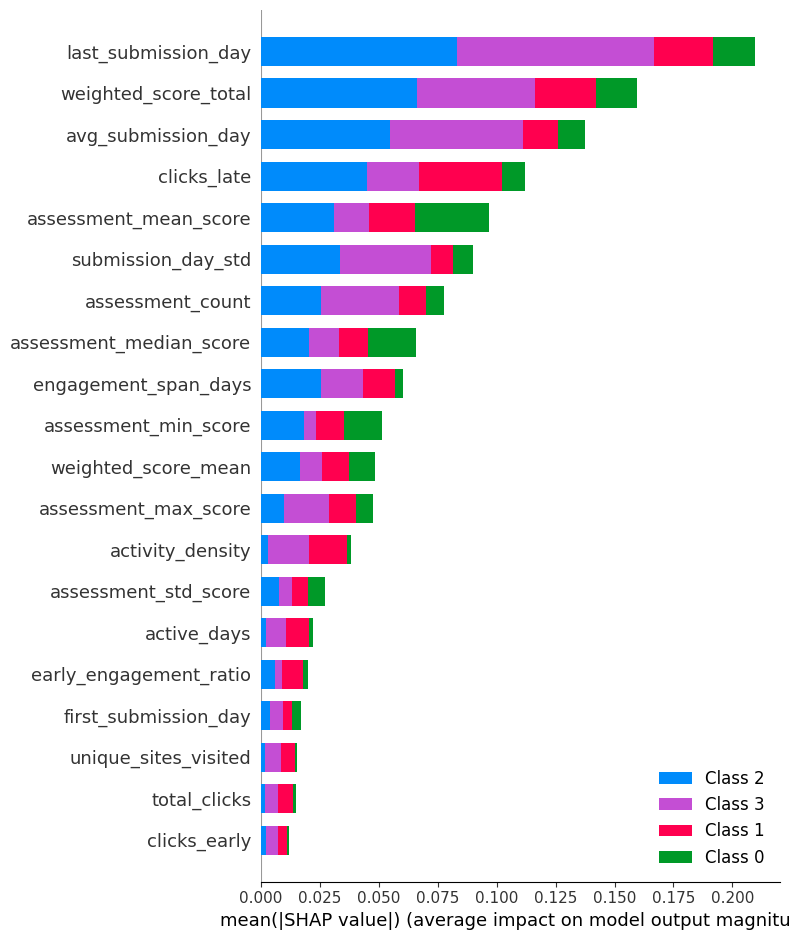

In [198]:
shap.summary_plot(
    shap_values,
    X_shap,
    plot_type="bar"
)

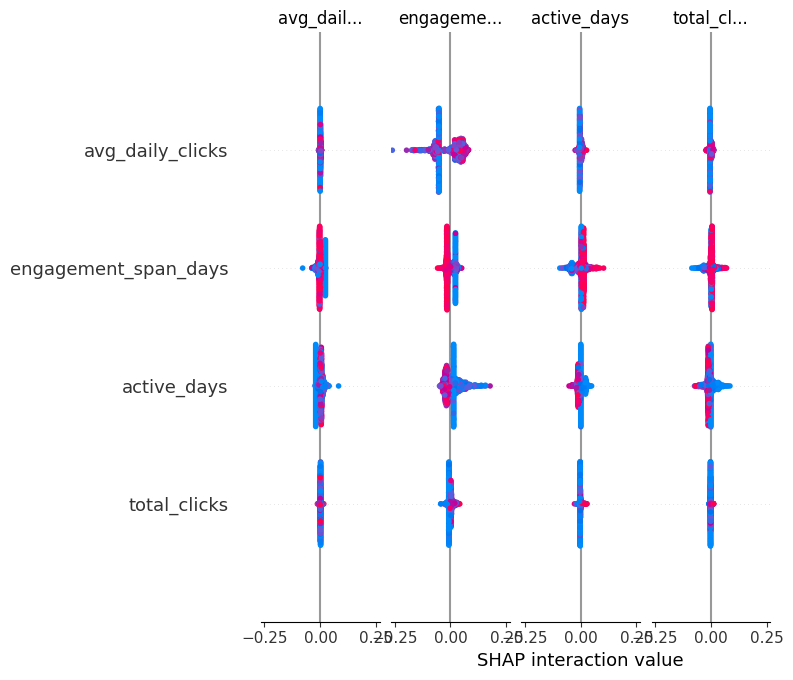

In [199]:
shap.summary_plot(
    shap_values,
    X_shap
)

advanced model comparison

In [200]:
model_results = pd.DataFrame({

    "Model":[
        "Random Forest",
        "Neural Network",
        "Gradient Boosting",
        "XGBoost"
    ],

    "Accuracy":[
        rf_accuracy,
        nn_accuracy,
        gb_accuracy,
        xgb_accuracy
    ]
})

model_results.sort_values(
    "Accuracy",
    ascending=False
)

,Model,Accuracy
1,Neural Network,0.714987
2,Gradient Boosting,0.707164
3,XGBoost,0.706397
0,Random Forest,0.706243


In [201]:
risk_mapping = {

    "High Achievers":"Low",

    "Consistent Learners":"Medium-Low",

    "Academically At-Risk Students":"Medium",

    "Struggling Learners":"High",

    "Early Dropouts":"Critical"
}

student_df["risk_level"] = (
    student_df["cluster_name"]
    .map(risk_mapping)
)

KeyError: 'cluster_name'

In [203]:
print(student_df.columns.tolist())

['code_module', 'code_presentation', 'id_student', 'gender', 'region', 'highest_education', 'imd_band', 'age_band', 'num_of_prev_attempts', 'studied_credits', 'disability', 'final_result', 'total_clicks', 'active_days', 'avg_daily_clicks', 'engagement_span_days', 'activity_density', 'click_std', 'daily_click_mean', 'click_cv', 'unique_sites_visited', 'clicks_early', 'clicks_mid', 'clicks_late', 'early_engagement_ratio', 'assessment_mean_score', 'assessment_median_score', 'assessment_max_score', 'assessment_min_score', 'assessment_std_score', 'assessment_count', 'weighted_score_total', 'weighted_score_mean', 'avg_submission_day', 'first_submission_day', 'last_submission_day', 'submission_day_std']


In [204]:
student_df = pd.read_csv(
    "data/processed/student_clustered.csv"
)

In [205]:
student_df = pd.read_csv(
    "data/processed/student_clustered.csv"
)

In [206]:
print(student_df.columns.tolist())

['code_module', 'code_presentation', 'id_student', 'gender', 'region', 'highest_education', 'imd_band', 'age_band', 'num_of_prev_attempts', 'studied_credits', 'disability', 'final_result', 'total_clicks', 'active_days', 'avg_daily_clicks', 'engagement_span_days', 'activity_density', 'click_std', 'daily_click_mean', 'click_cv', 'unique_sites_visited', 'clicks_early', 'clicks_mid', 'clicks_late', 'early_engagement_ratio', 'assessment_mean_score', 'assessment_median_score', 'assessment_max_score', 'assessment_min_score', 'assessment_std_score', 'assessment_count', 'weighted_score_total', 'weighted_score_mean', 'avg_submission_day', 'first_submission_day', 'last_submission_day', 'submission_day_std', 'cluster', 'cluster_name', 'risk_level', 'risk_score', 'low_engagement_flag', 'low_activity_flag', 'low_assessment_flag', 'poor_score_flag', 'late_submission_flag', 'behavior_risk_index', 'intervention_category', 'recommendation_1', 'recommendation_2', 'recommendation_3', 'recommendation_4']


In [207]:
risk_mapping = {

    "High Achievers": "Low",

    "Consistent Learners": "Medium-Low",

    "Academically At-Risk Students": "Medium",

    "Struggling Learners": "High",

    "Early Dropouts": "Critical"
}

student_df["risk_level"] = (
    student_df["cluster_name"]
    .map(risk_mapping)
)

student_df["risk_level"].value_counts()

risk_level
Medium-Low    13574
Medium         6391
Low            5462
High           4273
Critical       2893
Name: count, dtype: int64

In [208]:
intervention_mapping = {

    "High Achievers":
        "Advanced coursework, leadership opportunities, research projects.",

    "Consistent Learners":
        "Regular monitoring and skill enrichment activities.",

    "Academically At-Risk Students":
        "Targeted tutoring, assessment support, academic counseling.",

    "Struggling Learners":
        "Weekly mentoring, intensive tutoring, engagement monitoring.",

    "Early Dropouts":
        "Immediate outreach, retention counseling, personalized support plan."
}

student_df["recommended_intervention"] = (
    student_df["cluster_name"]
    .map(intervention_mapping)
)

In [209]:
intervention_mapping = {

    "High Achievers":
        "Advanced coursework, leadership opportunities, research projects.",

    "Consistent Learners":
        "Regular monitoring and skill enrichment activities.",

    "Academically At-Risk Students":
        "Targeted tutoring, assessment support, academic counseling.",

    "Struggling Learners":
        "Weekly mentoring, intensive tutoring, engagement monitoring.",

    "Early Dropouts":
        "Immediate outreach, retention counseling, personalized support plan."
}

student_df["recommended_intervention"] = (
    student_df["cluster_name"]
    .map(intervention_mapping)
)

In [210]:
student_df.to_csv(
    "data/processed/student_intervention_dataset.csv",
    index=False
)

print("Intervention dataset saved")

Intervention dataset saved


In [211]:
print("RF Features:", rf_model.n_features_in_)
print("X_train:", X_train_clean.shape)
print("X_test:", X_test_clean.shape)

RF Features: 25
X_train: (26074, 25)
X_test: (6519, 25)


In [212]:
import shap

X_shap = X_test_clean.sample(
    n=1000,
    random_state=42
)

print(X_shap.shape)

(1000, 25)


In [213]:
explainer = shap.TreeExplainer(
    rf_model
)

print("Explainer Created")

Explainer Created


In [214]:
shap_values = explainer.shap_values(
    X_shap,
    check_additivity=False
)

In [215]:
print(type(shap_values))
print(np.array(shap_values).shape)

<class 'numpy.ndarray'>
(1000, 25, 4)


In [216]:
import numpy as np
import pandas as pd

mean_abs_shap = np.abs(shap_values).mean(axis=(0,2))

shap_importance = pd.DataFrame({

    "feature": X_shap.columns,
    "mean_abs_shap": mean_abs_shap

})

shap_importance = shap_importance.sort_values(
    "mean_abs_shap",
    ascending=False
)

shap_importance.head(15)

,feature,mean_abs_shap
23,last_submission_day,0.052422
19,weighted_score_total,0.039892
21,avg_submission_day,0.034394
11,clicks_late,0.027988
13,assessment_mean_score,0.024142
24,submission_day_std,0.022482
18,assessment_count,0.019391
14,assessment_median_score,0.016423
3,engagement_span_days,0.015029
16,assessment_min_score,0.012807


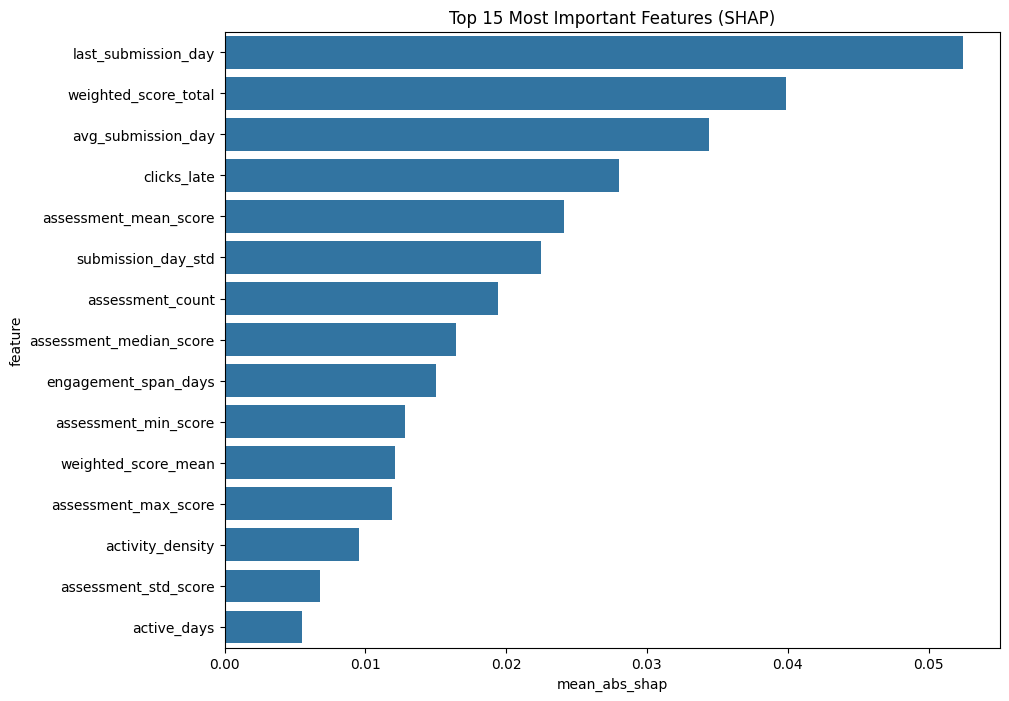

In [217]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,8))

sns.barplot(

    data=shap_importance.head(15),

    x="mean_abs_shap",

    y="feature"

)

plt.title(
    "Top 15 Most Important Features (SHAP)"
)

plt.show()

In [218]:
pass_class = list(
    label_encoder.classes_
).index("Pass")

pass_importance = pd.DataFrame({

    "feature": X_shap.columns,

    "importance":
        np.abs(
            shap_values[:,:,pass_class]
        ).mean(axis=0)

})

pass_importance.sort_values(
    "importance",
    ascending=False
).head(15)

,feature,importance
23,last_submission_day,0.083097
19,weighted_score_total,0.066199
21,avg_submission_day,0.054657
11,clicks_late,0.045167
24,submission_day_std,0.033696
13,assessment_mean_score,0.030963
3,engagement_span_days,0.025508
18,assessment_count,0.025390
14,assessment_median_score,0.020441
16,assessment_min_score,0.018198


In [219]:
fail_class = list(
    label_encoder.classes_
).index("Fail")

fail_importance = pd.DataFrame({

    "feature": X_shap.columns,

    "importance":
        np.abs(
            shap_values[:,:,fail_class]
        ).mean(axis=0)

})

fail_importance.sort_values(
    "importance",
    ascending=False
).head(15)

,feature,importance
11,clicks_late,0.035023
19,weighted_score_total,0.026094
23,last_submission_day,0.025330
13,assessment_mean_score,0.019438
4,activity_density,0.015991
21,avg_submission_day,0.014959
3,engagement_span_days,0.013620
14,assessment_median_score,0.012317
15,assessment_max_score,0.011833
16,assessment_min_score,0.011832


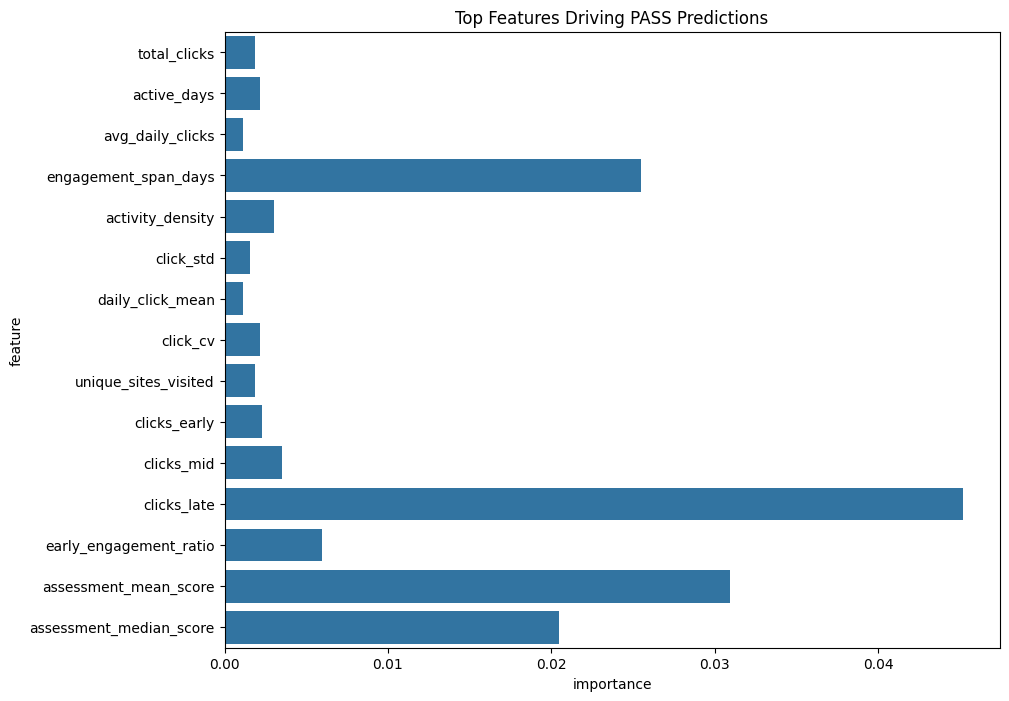

In [220]:
plt.figure(figsize=(10,8))

sns.barplot(

    data=
    pass_importance.head(15),

    x="importance",

    y="feature"

)

plt.title(
    "Top Features Driving PASS Predictions"
)

plt.show()

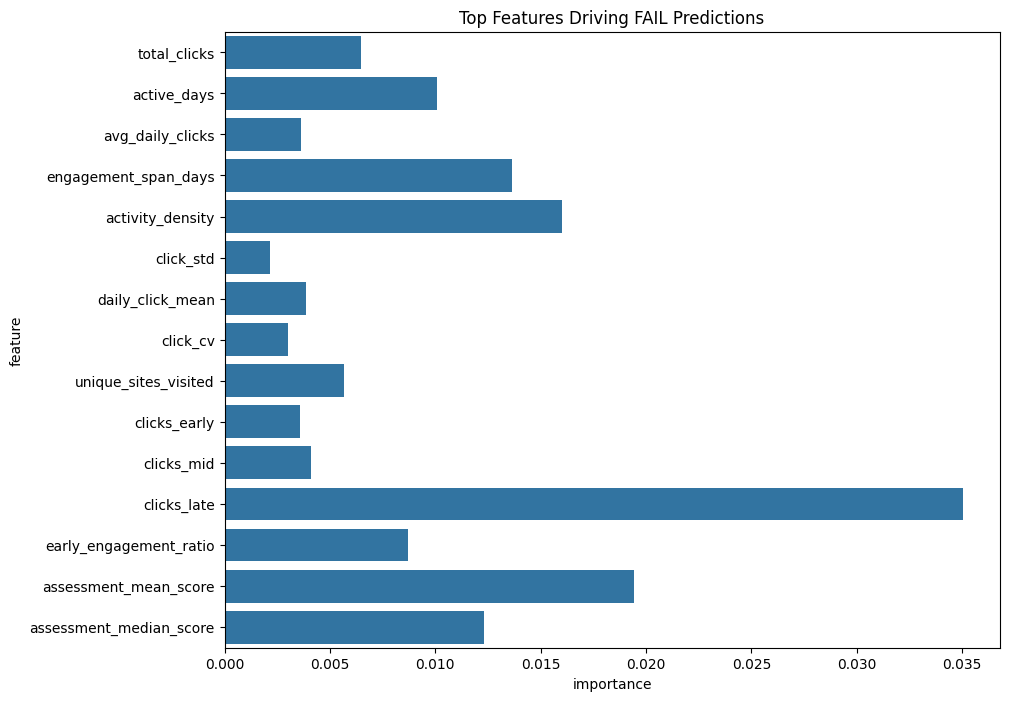

In [221]:
plt.figure(figsize=(10,8))

sns.barplot(

    data=
    fail_importance.head(15),

    x="importance",

    y="feature"

)

plt.title(
    "Top Features Driving FAIL Predictions"
)

plt.show()

In [222]:
student_index = 0

In [223]:
student_features = X_shap.iloc[
    student_index
]

student_shap = shap_values[
    student_index
]

print(
    student_features
)

total_clicks               8815.000000
active_days                 214.000000
avg_daily_clicks             41.191589
engagement_span_days        258.000000
activity_density              0.829457
click_std                    47.684071
daily_click_mean             41.191589
click_cv                      1.157617
unique_sites_visited        156.000000
clicks_early               3326.000000
clicks_mid                 4035.000000
clicks_late                1454.000000
early_engagement_ratio        0.377311
assessment_mean_score        84.000000
assessment_median_score      82.000000
assessment_max_score        100.000000
assessment_min_score         70.000000
assessment_std_score          8.817596
assessment_count              9.000000
weighted_score_total        162.820000
weighted_score_mean          18.091111
avg_submission_day          128.444444
first_submission_day         20.000000
last_submission_day         234.000000
submission_day_std           77.995370
Name: 9951, dtype: float6

In [224]:
student_explanation = pd.DataFrame({

    "feature":
        X_shap.columns,

    "Distinction":
        student_shap[:,0],

    "Fail":
        student_shap[:,1],

    "Pass":
        student_shap[:,2],

    "Withdrawn":
        student_shap[:,3]
})

student_explanation.head()

,feature,Distinction,Fail,Pass,Withdrawn
0,total_clicks,0.002618,-0.005710,0.000287,0.002804
1,active_days,0.003113,-0.011098,0.001322,0.006663
2,avg_daily_clicks,0.000899,0.002919,-0.002345,-0.001473
3,engagement_span_days,0.000522,-0.009371,0.025764,-0.016915
4,activity_density,0.004426,-0.013894,-0.006170,0.015638


In [225]:
shap_importance.to_csv(

    "data/processed/shap_feature_importance.csv",

    index=False
)

print(
    "SHAP Feature Importance Saved"
)

SHAP Feature Importance Saved


In [226]:
model_comparison = pd.DataFrame({

    "Model":[
        "Random Forest",
        "Neural Network",
        "Gradient Boosting",
        "XGBoost"
    ],

    "Accuracy":[
        rf_accuracy,
        nn_accuracy,
        gb_accuracy,
        xgb_accuracy
    ]
})

model_comparison = model_comparison.sort_values(
    "Accuracy",
    ascending=False
)

model_comparison

,Model,Accuracy
1,Neural Network,0.714987
2,Gradient Boosting,0.707164
3,XGBoost,0.706397
0,Random Forest,0.706243


In [227]:
model_comparison.to_csv(
    "data/processed/model_comparison.csv",
    index=False
)

In [228]:
import joblib

joblib.dump(
    rf_model,
    "models/final_random_forest.pkl"
)

joblib.dump(
    xgb_model,
    "models/final_xgboost.pkl"
)

joblib.dump(
    kmeans,
    "models/final_kmeans.pkl"
)

print("All final models saved")

NameError: name 'kmeans' is not defined

In [229]:
import joblib

joblib.dump(
    rf_model,
    "models/final_random_forest.pkl"
)

joblib.dump(
    xgb_model,
    "models/final_xgboost.pkl"
)

print("Models saved successfully")

Models saved successfully


In [230]:
import os

print(os.listdir("models"))

['final_kmeans.pkl', 'final_random_forest.pkl', 'final_xgboost.pkl', 'label_encoder.pkl', 'persona_predictor.pkl', 'random_forest.pkl', 'scaler.pkl']


In [231]:
print(student_df.columns.tolist())

['code_module', 'code_presentation', 'id_student', 'gender', 'region', 'highest_education', 'imd_band', 'age_band', 'num_of_prev_attempts', 'studied_credits', 'disability', 'final_result', 'total_clicks', 'active_days', 'avg_daily_clicks', 'engagement_span_days', 'activity_density', 'click_std', 'daily_click_mean', 'click_cv', 'unique_sites_visited', 'clicks_early', 'clicks_mid', 'clicks_late', 'early_engagement_ratio', 'assessment_mean_score', 'assessment_median_score', 'assessment_max_score', 'assessment_min_score', 'assessment_std_score', 'assessment_count', 'weighted_score_total', 'weighted_score_mean', 'avg_submission_day', 'first_submission_day', 'last_submission_day', 'submission_day_std', 'cluster', 'cluster_name', 'risk_level', 'risk_score', 'low_engagement_flag', 'low_activity_flag', 'low_assessment_flag', 'poor_score_flag', 'late_submission_flag', 'behavior_risk_index', 'intervention_category', 'recommendation_1', 'recommendation_2', 'recommendation_3', 'recommendation_4', '

In [232]:
final_dashboard_df = student_df[[
    "id_student",
    "final_result",
    "cluster",
    "cluster_name",
    "risk_level",
    "risk_score",
    "behavior_risk_index",
    "intervention_category",
    "recommended_intervention"
]]

final_dashboard_df.head()

,id_student,final_result,cluster,cluster_name,risk_level,risk_score,behavior_risk_index,intervention_category,recommended_intervention
0,11391,Pass,4,Consistent Learners,Medium-Low,2,0,Performance Enhancement,Regular monitoring and skill enrichment activi...
1,28400,Pass,4,Consistent Learners,Medium-Low,2,0,Performance Enhancement,Regular monitoring and skill enrichment activi...
2,30268,Withdrawn,0,Struggling Learners,High,4,3,Moderate Support,"Weekly mentoring, intensive tutoring, engageme..."
3,31604,Pass,4,Consistent Learners,Medium-Low,2,0,Performance Enhancement,Regular monitoring and skill enrichment activi...
4,32885,Pass,4,Consistent Learners,Medium-Low,2,1,Performance Enhancement,Regular monitoring and skill enrichment activi...


In [234]:
final_dashboard_df.shape

(32593, 9)

In [233]:
final_dashboard_df.to_csv(
    "data/processed/student_analytics_dashboard.csv",
    index=False
)

print("Dashboard dataset saved")

Dashboard dataset saved


In [235]:
print("Total Students:", len(student_df))

print(
    "Critical Risk Students:",
    (student_df["risk_level"] == "Critical").sum()
)

print(
    "High Risk Students:",
    (student_df["risk_level"] == "High").sum()
)

print(
    "Average Behavior Risk Index:",
    round(student_df["behavior_risk_index"].mean(), 2)
)

Total Students: 32593
Critical Risk Students: 2893
High Risk Students: 4273
Average Behavior Risk Index: 1.2


In [236]:
student_df["behavior_risk_index"].describe()

count    32593.000000
mean         1.200472
std          1.436580
min          0.000000
25%          0.000000
50%          1.000000
75%          2.000000
max          4.000000
Name: behavior_risk_index, dtype: float64

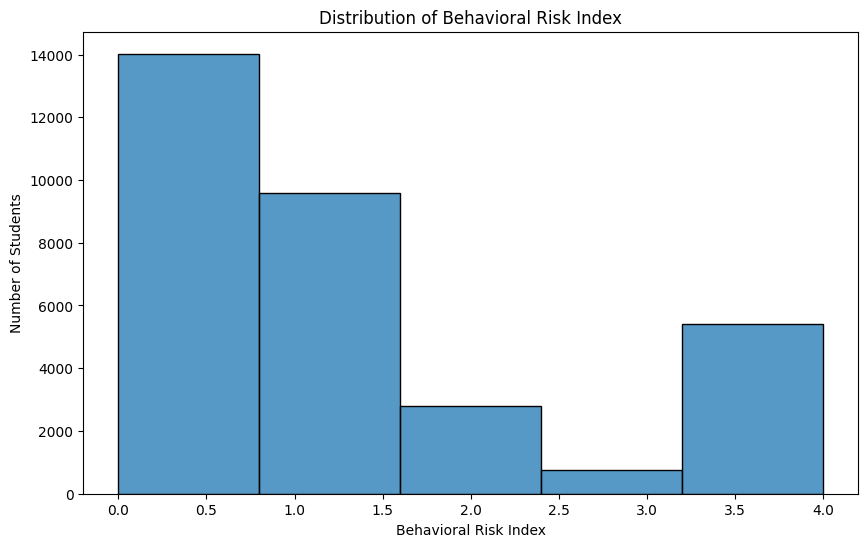

In [237]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,6))

sns.histplot(
    student_df["behavior_risk_index"],
    bins=5
)

plt.title(
    "Distribution of Behavioral Risk Index"
)

plt.xlabel(
    "Behavioral Risk Index"
)

plt.ylabel(
    "Number of Students"
)

plt.show()